In [2]:
import pandas as pd
import datetime


# Data

In [3]:
min15 = pd.read_parquet('../Dataset/15min_btc_sentiment.parquet', engine="pyarrow")
hr1 = pd.read_parquet('../Dataset/1h_btc_sentiment.parquet', engine="pyarrow")

In [4]:
min15.head()

,Open,High,Low,Close,Volume,return,return_class,avg_score,n_positive,n_negative,total_tweets,net_sentiment,sentiment_mode,sentiment_mean,sentiment_median,sentiment_weighted
datetime,,,,,,,,,,,,,,,,
2021-01-01 00:00:00+00:00,28908.84,28928.51,28776.17,28840.00,160.774265,NaN,1,0.471976,6,273,400,-267,negative,-0.667500,negative,-0.684340
2021-01-01 00:15:00+00:00,28825.70,28989.78,28825.70,28984.38,47.317326,0.005006,2,0.466221,3,194,286,-191,negative,-0.667832,negative,-0.684950
2021-01-01 00:30:00+00:00,28984.33,29052.03,28945.26,28958.84,60.117640,-0.000881,1,0.467470,5,229,313,-224,negative,-0.715655,negative,-0.730766
2021-01-01 00:45:00+00:00,28971.86,29045.70,28910.00,28949.03,82.298676,-0.000339,1,0.469825,4,180,273,-176,negative,-0.644689,negative,-0.662580
2021-01-01 01:00:00+00:00,28949.71,29045.70,28921.64,29036.58,86.369610,0.003024,2,0.470017,2,201,324,-199,negative,-0.614198,negative,-0.628105


In [15]:
df = min15.copy()

In [16]:
mapping = {'negative': 0, 'neutral': 1}
df['sentiment_num'] = df['sentiment_mode'].map(mapping)

In [ ]:
df['lag1'] = df['Close'].shift(1)
df['lag4'] = df['Close'].shift(4)
df['lag8'] = df['Close'].shift(8)
df['return'] = df['Close'].pct_change()
df['volatility_4'] = df['return'].rolling(4).std()
df['sma_4'] = df['Close'].rolling(4).mean()
df['sma_8'] = df['Close'].rolling(8).mean()

df['target_return'] = df['return'].shift(-1)
df['target_up'] = (df['target_return'] > 0).astype(int)
df = df.dropna()


# Random forest

In [ ]:
features = [
    'lag1', 'lag4', 'lag8',
    'return', 'volatility_4',
    'sma_4', 'sma_8', 
    'sentiment_num']

X = df[features]
y_reg = df['target_return']
y_clf = df['target_up']


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y_clf, shuffle=False, test_size=0.3
)

model = RandomForestClassifier()
model.fit(X_train, y_train)

print("Accuracy:", model.score(X_test, y_test))

Accuracy: 0.507011351712296


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_clf, shuffle=False, test_size=0.3
)

model = RandomForestClassifier()
model.fit(X_train, y_train)

print("Accuracy with sentiment:", model.score(X_test, y_test))

Accuracy with sentiment: 0.5048636276940682


# XAI test

In [ ]:
from interpret import show
from interpret.glassbox import ExplainableBoostingClassifier
from interpret import set_visualize_provider
from interpret.provider import InlineProvider

set_visualize_provider(InlineProvider())

features = [
    'lag1', 'lag4', 'lag8',
    'return', 'volatility_4',
    'sma_4', 'sma_8', 'sentiment_num',
    'sentiment_mode']

X = df[features]
y_reg = df['target_return']
y_clf = df['target_up']

X_train, X_test, y_train, y_test = train_test_split(
    X, y_clf, shuffle=False, test_size=0.3
)


In [27]:
X[X['sentiment_mode']!= 'negative']

,lag1,lag4,lag8,return,volatility_4,sma_4,sma_8,sentiment_num,sentiment_mode
datetime,,,,,,,,,
2021-01-19 01:30:00+00:00,36027.96,35902.24,35875.97,0.006911,0.004248,36045.7575,35973.28250,1.0,neutral
2021-01-19 01:45:00+00:00,36276.94,35996.26,35797.47,-0.004029,0.005388,36079.3875,36014.94625,1.0,neutral
2021-01-19 02:00:00+00:00,36130.78,35881.87,36006.12,0.001783,0.004643,36157.7225,36038.58250,1.0,neutral
2021-01-19 02:15:00+00:00,36195.21,36027.96,35897.40,-0.000948,0.004641,36190.9550,36071.51875,1.0,neutral
2021-01-19 02:30:00+00:00,36160.89,36276.94,35902.24,0.001300,0.002652,36173.6975,36109.72750,1.0,neutral
...,...,...,...,...,...,...,...,...,...
2021-03-31 12:00:00+00:00,58192.86,59600.00,58716.33,-0.006980,0.008924,58683.7775,59134.42250,1.0,neutral
2021-03-31 13:45:00+00:00,57961.43,57999.12,58192.86,0.000220,0.002435,58052.6250,57961.32875,1.0,neutral
2021-03-31 14:30:00+00:00,57464.59,57961.43,57794.31,0.003682,0.004928,57761.3675,57910.11125,1.0,neutral


In [ ]:
ebm = ExplainableBoostingClassifier()
ebm.fit(X_train, y_train)

,feature_names,None
,feature_types,None
,max_bins,1024
,max_interaction_bins,64
,interactions,'3x'
,exclude,None
,validation_size,0.15
,outer_bags,14
,inner_bags,0
,learning_rate,0.015
,greedy_ratio,10.0


In [30]:
ebm_global = ebm.explain_global(name='test')
show(ebm_global)

In [31]:
print("Accuracy:", ebm.score(X_test, y_test))

Accuracy: 0.5281327484264734


In [32]:
ebm_local = ebm.explain_local(X_test[:5], y_test[:5], name='EBM')
show(ebm_local, 0)

# Test with Ostap data

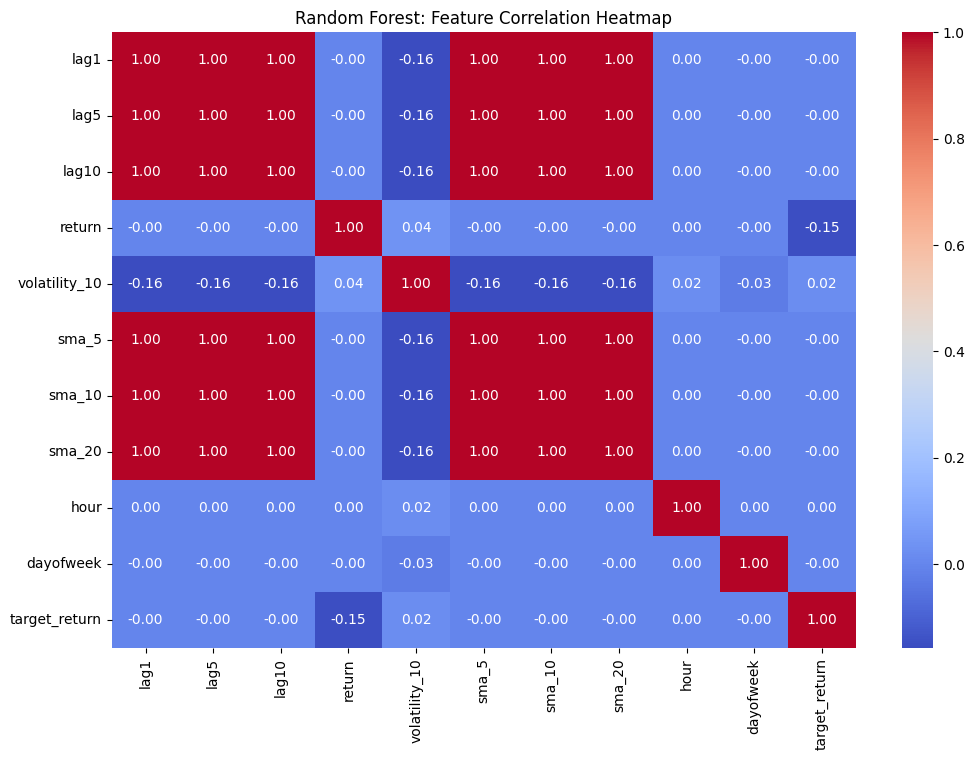

--- RESULTS RANDOM FOREST ---
MAE (Regression): 0.000396
R2 Score: -0.005452
Accuracy: 0.5405
F1-Score: 0.0703
Area Under the Curve (AUC): 0.5265


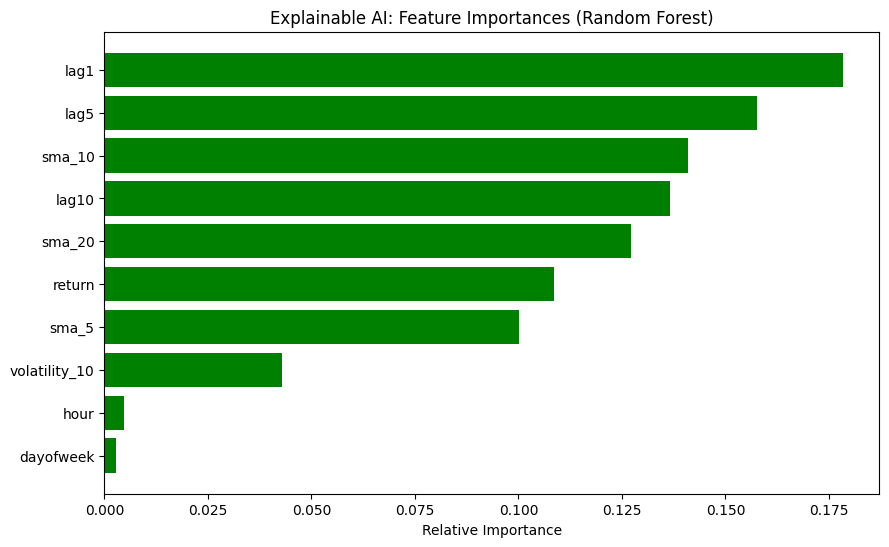


Example next-minute prediction:
Real return: 0.000991 | Predicted: -0.000024
Real direction: 1 | Predicted: 0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (mean_absolute_error, accuracy_score, r2_score, f1_score, roc_auc_score)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

df = pd.read_csv("../Dataset/btcusd_1-min_data.csv")  
df['Timestamp'] = pd.to_datetime(df['Timestamp'], unit='s')
df = df.sort_values('Timestamp').reset_index(drop=True)

df['lag1'] = df['Close'].shift(1)
df['lag5'] = df['Close'].shift(5)
df['lag10'] = df['Close'].shift(10)
df['return'] = df['Close'].pct_change()
df['volatility_10'] = df['return'].rolling(10).std()
df['sma_5'] = df['Close'].rolling(5).mean()
df['sma_10'] = df['Close'].rolling(10).mean()
df['sma_20'] = df['Close'].rolling(20).mean()
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek

df['target_return'] = df['return'].shift(-1)
df['target_up'] = (df['target_return'] > 0).astype(int)
df = df.dropna()

features = [
    'lag1', 'lag5', 'lag10',
    'return', 'volatility_10',
    'sma_5', 'sma_10', 'sma_20',
    'hour', 'dayofweek'
]

X = df[features]
y_reg = df['target_return']
y_clf = df['target_up']

plt.figure(figsize=(12, 8))

corr_matrix = df[features + ['target_return']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Random Forest: Feature Correlation Heatmap")
plt.savefig("rf_heatmap.png")
plt.show()

X_train, X_test, y_train_reg, y_test_reg = train_test_split(X, y_reg, test_size=0.2, shuffle=False)
_, _, y_train_clf, y_test_clf = train_test_split(X, y_clf, test_size=0.2, shuffle=False)

X_train_sub = X_train.iloc[::10]
y_train_reg_sub = y_train_reg.iloc[::10]
y_train_clf_sub = y_train_clf.iloc[::10]


"""
param_dist = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
random_search = RandomizedSearchCV(RandomForestClassifier(), param_distributions=param_dist, n_iter=5, cv=3)
random_search.fit(X_train_sub, y_train_clf_sub)
print(f"Best parameters: {random_search.best_params_}")
"""

reg_model = RandomForestRegressor(n_estimators=50, max_depth=6, n_jobs=-1, random_state=42)
reg_model.fit(X_train_sub, y_train_reg_sub)

clf_model = RandomForestClassifier(n_estimators=50, max_depth=6, n_jobs=-1, random_state=42)
clf_model.fit(X_train_sub, y_train_clf_sub)

pred_reg = reg_model.predict(X_test)
pred_clf = clf_model.predict(X_test)
pred_proba = clf_model.predict_proba(X_test)[:, 1]

mae = mean_absolute_error(y_test_reg, pred_reg)
r2 = r2_score(y_test_reg, pred_reg)
acc = accuracy_score(y_test_clf, pred_clf)
f1 = f1_score(y_test_clf, pred_clf)
auc = roc_auc_score(y_test_clf, pred_proba)

print(f"--- RESULTS RANDOM FOREST ---")
print(f"MAE (Regression): {mae:.6f}")
print(f"R2 Score: {r2:.6f}")
print(f"Accuracy: {acc:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Area Under the Curve (AUC): {auc:.4f}")

plt.figure(figsize=(10, 6))
importances = clf_model.feature_importances_
indices = np.argsort(importances)
plt.title('Explainable AI: Feature Importances (Random Forest)')
plt.barh(range(len(indices)), importances[indices], color='green', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.savefig("rf_feature_importance.png")
plt.show()

print("\nExample next-minute prediction:")
print(f"Real return: {y_test_reg.values[-1]:.6f} | Predicted: {pred_reg[-1]:.6f}")
print(f"Real direction: {y_test_clf.values[-1]} | Predicted: {pred_clf[-1]}")